<a href="https://colab.research.google.com/github/x72g9hmdhf-bot/analysis_everpeak/blob/main/S5_ladb_mobility_economy_project_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Introducción

Como analista de datos, tu objetivo es **evaluar cómo la movilidad urbana se relaciona con la productividad económica en las principales ciudades latinoamericanas**.
Para ello trabajarás con datos reales de TomTom Traffic Index y OECD Cities, que deberás limpiar, combinar y analizar para identificar en qué ciudades conviene invertir en infraestructura de transporte.

## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de ambos datasets**.
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯Objetivo:**
Importar las librerías necesarias, cargar los archivos CSV en DataFrames y realizar una revisión preliminar para entender su contenido.

**Instrucciones:**
- Importa las librerías `pandas`, `numpy`, `seaborn` y `matplotlib.pyplot`.
- Carga los archivos usando `pd.read_csv()`:
  - `'/datasets/tomtom_traffic.csv'`
  - `/datasets/oecd_city_economy.csv` `.
- Guarda los DataFrames en las variables `traffic` y `eco`.
- Muestra las primeras 5 filas de cada DataFrame.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
# importar librerías

In [ ]:
# cargar archivos
traffic = pd.read_csv('/datasets/tomtom_traffic.csv')
eco = pd.read_csv('/datasets/oecd_city_economy.csv')
#completa el código

In [ ]:
traffic.head(5) # mostrar las primeras 5 filas de traffic

,Country,City,UpdateTimeUTC,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232
3,ARE,abu-dhabi,2025-01-13 01:46:30.001,8.2,2.0,4.1,2.0,2.0,2025-01-06 01:46:30.000,7.723808,7.899046,-0.175238
4,ARE,abu-dhabi,2025-01-13 00:01:30.000,1.1,1.0,0.2,1.0,1.0,2025-01-06 00:01:30.000,8.336363,8.604379,-0.268016


In [ ]:
 eco.head(5) # mostrar las primeras 5 filas de eco

,Year,City,Country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M)
0,2023,buenos-aires,Argentina,"15.782,00",6.2%,"15,2","15,30"
1,2023,sao-paulo,Brazil,"14.475,00",9.1%,"29,50","22,50"
2,2023,rio-de-janeiro,Brazil,"13.142,00",9.8%,"19,10","13,60"
3,2023,brasilia,Brazil,"15.999,00",8.3%,"13,50","4,70"
4,2023,salvador,Brazil,"8.761,00",13.1%,"16,00","3,90"


<div class="alert alert-block alert-success">
<b>Comentario del Revisor [1° iteración]</b> <a class="tocSkip"></a><br>
<b>Éxito</b>

Muy bien visualizadas las primeras filas del dataset económico para identificar los tipos de datos y valores.
</div>

**Tip:** Si no usas `print()` la tabla se vera mejor.


---

## 🧩Paso 2: Explorar, limpiar y preparar los datos

Antes de combinar los datasets, inspecciona su estructura, tipos de datos, columnas y valores faltantes.
Anota las columnas que necesiten limpieza y luego estandariza los nombres de columnas.

### 2.1 Explorar la estructura y tipos de datos

**🎯Objetivo:**
Identificar columnas con tipos incorrectos, distribución y nulos, anotar las columnas que requieren conversión.

**Instrucciones:**

- Usa `.info()` para conocer la estructura de ambos DataFrames.
- Muestra los primeros 3 renglones de cada DF.
- Identifica si los detalles de cada DF estan bien o si requieren correcciones y escribe tus conclusiones en el bloque Markdown.
  - ¿Hay columnas que requieren conversión?¿ Cuáles son? ¿Que tipo de dato ienen y cuál deberían de tener?
  - ¿Hay datos ausentes en alguna columna?


In [ ]:
traffic.info()# Examinar la estructura de traffic


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   Country                         1004464 non-null  object 
 1   City                            1004464 non-null  object 
 2   UpdateTimeUTC                   1004464 non-null  object 
 3   JamsDelay                       1004464 non-null  float64
 4   TrafficIndexLive                1004464 non-null  float64
 5   JamsLengthInKms                 1004464 non-null  float64
 6   JamsCount                       1004464 non-null  float64
 7   TrafficIndexWeekAgo             1004464 non-null  float64
 8   UpdateTimeUTCWeekAgo            1004464 non-null  object 
 9   TravelTimeLivePer10KmsMins      1004464 non-null  float64
 10  TravelTimeHistoricPer10KmsMins  1004464 non-null  float64
 11  MinsDelay                       1004464 non-null  float64
dtype

In [ ]:
eco.info() # Examinar la estructura de eco


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Year             30 non-null     int64 
 1   City             30 non-null     object
 2   Country          30 non-null     object
 3   City GDP/capita  30 non-null     object
 4   Unemployment %   30 non-null     object
 5   PM2.5 (μg/m³)    30 non-null     object
 6   Population (M)   30 non-null     object
dtypes: int64(1), object(6)
memory usage: 1.8+ KB


### 2.2 Renombrar columnas

**🎯Objetivo:**
Estandarizar los nombres de columnas para evitar errores y facilitar la unión de los datasets.

**Instrucciones:**

- Cambia los nombres de las columnas para que tengan el formato `snake_case`.
    - `Country` → `country`
    - `UpdateTimeUTC` → `update_time_utc`
- Verifica que los cambios se hayan aplicado correctamente usando `.columns`.


In [ ]:
# Estandarizar los nombres de las columnas de traffic
traffic=traffic.rename(columns={'Country':'country','UpdateTimeUTC':'update_time_utc'})   #tu código aquí

# verificar cambios
traffic.columns

Index(['country', 'City', 'update_time_utc', 'JamsDelay', 'TrafficIndexLive',
       'JamsLengthInKms', 'JamsCount', 'TrafficIndexWeekAgo',
       'UpdateTimeUTCWeekAgo', 'TravelTimeLivePer10KmsMins',
       'TravelTimeHistoricPer10KmsMins', 'MinsDelay'],
      dtype='object')

In [ ]:
# Estandarizar los nombres de las columnas de eco
eco=eco.rename(columns={'Country':'country','City GDP/capita':'city_gdp_capita','PM2.5 (μg/m³)':'pm2.5_(μg/m³)','Population (M)':'population','Unemployment %':'unemployment_pct','Year':'year'})   #tu código aquí

# verificar cambios
eco.columns

Index(['year', 'City', 'country', 'city_gdp_capita', 'unemployment_pct',
       'pm2.5_(μg/m³)', 'population'],
      dtype='object')


### 2.3 Corregir formatos numéricos y de fecha

**🎯Objetivo:**
Asegurar que las columnas de fechas y valores numéricos estén en formatos correctos para permitir análisis, cálculos y comparaciones precisas.

**Instrucciones:**

- Convierte las columnas de fecha de `traffic` a formato `datetime`. Haz el cambio a prueba de errores.
- En el dataset `eco`, limpia los valores numéricos:
    - En `city_gdp_capita`: elimina separadores de miles (`.`) y reemplaza las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
    - En `unemployment_pct`: elimina el símbolo de porcentaje (`%`) y reemplaza las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
    - En `population_m`: reemplaza las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
- Finalmente, crea una nueva columna llamada `population` multiplicando `population_m` por 1,000,000 para obtener la población total.


<details>
<summary>Haz clic para ver la pista</summary>
para eliminar símbolos, puedes reemplazarlos por un texto vacío.

In [ ]:
# Convertir las columnas de traffic a tipo fecha con pd.to_datetime()

traffic['update_time_utc']=pd.to_datetime(traffic['update_time_utc'],errors='coerce') #tu código aquí
traffic['UpdateTimeUTCWeekAgo'] = pd.to_datetime(traffic['UpdateTimeUTCWeekAgo'],errors='coerce')


# verificar el cambio
traffic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                          Non-Null Count    Dtype         
---  ------                          --------------    -----         
 0   country                         1004464 non-null  object        
 1   City                            1004464 non-null  object        
 2   update_time_utc                 1004464 non-null  datetime64[ns]
 3   JamsDelay                       1004464 non-null  float64       
 4   TrafficIndexLive                1004464 non-null  float64       
 5   JamsLengthInKms                 1004464 non-null  float64       
 6   JamsCount                       1004464 non-null  float64       
 7   TrafficIndexWeekAgo             1004464 non-null  float64       
 8   UpdateTimeUTCWeekAgo            1004464 non-null  datetime64[ns]
 9   TravelTimeLivePer10KmsMins      1004464 non-null  float64       
 10  TravelTimeHistoricPer10KmsMins  1004464 no

In [ ]:
# Limpia separadores y convierte columnas numéricas en eco
eco['city_gdp_capita'] = eco['city_gdp_capita'].astype(str).str.replace('.', '').str.replace(',', '.').astype(float)
eco['unemployment_pct'] =eco['unemployment_pct'].str.replace('%','').astype(float)
eco['population'] = eco['population'].str.replace(',','.').astype(float)

# Calcula la población total en unidades absolutas (Multiplica * 1000000)
eco['population'] = eco['population'] * 1000000

# verificar el cambio
eco.info()
eco.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   year              30 non-null     int64  
 1   City              30 non-null     object 
 2   country           30 non-null     object 
 3   city_gdp_capita   30 non-null     float64
 4   unemployment_pct  30 non-null     float64
 5   pm2.5_(μg/m³)     30 non-null     object 
 6   population        30 non-null     float64
dtypes: float64(3), int64(1), object(3)
memory usage: 1.8+ KB


,year,City,country,city_gdp_capita,unemployment_pct,pm2.5_(μg/m³),population
0,2023,buenos-aires,Argentina,15782.0,6.2,"15,2",15300000.0
1,2023,sao-paulo,Brazil,14475.0,9.1,"29,50",22500000.0
2,2023,rio-de-janeiro,Brazil,13142.0,9.8,"19,10",13600000.0



---

## 🧩Paso 3: Extraer año y filtrar

Extraer el año permite filtrar la información y trabajar solo con el período más reciente y relevante.

### 3.1 Extraer columna año y filtrar 2024

**🎯Objetivo**
Identificar el año de cada registro y mantener solo los registros del 2024.

**Intrucciones**

- Como el DataFrame `traffic` no tiene una columna de año, utiliza el atributo `.dt.year` sobre su columna de fecha para crear una nueva columna llamada `year`.
- Filtra las filas donde el año sea **2024**.
- Utiliza `.copy()` para crear dos nuevos DataFrames (`traffic_2024` y `eco_2024`) para evitar modificar el dataset original.

In [ ]:
# Extraer el año de las fechas en update_time_utc
traffic['year'] = traffic['update_time_utc'].dt.year

# Verificar cambio
traffic.head(3)

,country,City,update_time_utc,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay,year
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437,2025
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635,2025
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232,2025


<div class="alert alert-block alert-success">
<b>Comentario del Revisor [1° iteración]</b> <a class="tocSkip"></a><br>
<b>Éxito</b>

Muy bien extraído el año a partir de la columna de fecha para facilitar los filtros posteriores.
</div>

In [ ]:
# Filtra los registros del año 2024
traffic_2024 = traffic[traffic['year']==2024].copy()
eco_2024 = eco[eco['year']==2024].copy()
print(eco_2024.shape)
# Revisar dataframes nuevos
display(traffic_2024.head())
display(eco_2024.head())


(15, 7)


,country,City,update_time_utc,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay,year
302,ARE,abu-dhabi,2024-12-31 23:01:30.000,12.9,5.0,2.5,5.0,2.0,2024-12-24 23:01:30.001,8.560399,8.519634,0.040765,2024
303,ARE,abu-dhabi,2024-12-31 22:01:30.000,136.0,21.0,20.6,32.0,3.0,2024-12-24 22:01:30.000,10.355732,9.049445,1.306286,2024
304,ARE,abu-dhabi,2024-12-31 21:16:30.000,455.2,31.0,40.4,72.0,4.0,2024-12-24 21:01:30.000,11.456878,9.305174,2.151704,2024
305,ARE,abu-dhabi,2024-12-31 20:01:00.001,399.4,27.0,38.0,75.0,6.0,2024-12-24 20:01:30.001,11.670062,9.952811,1.717252,2024
306,ARE,abu-dhabi,2024-12-31 19:46:00.000,366.4,28.0,39.8,82.0,9.0,2024-12-24 19:01:00.000,11.686322,10.008469,1.677853,2024


,year,City,country,city_gdp_capita,unemployment_pct,pm2.5_(μg/m³),population
15,2024,buenos-aires,Argentina,18117.0,7.2,"14,50",15400000.0
16,2024,sao-paulo,Brazil,14703.0,8.5,"28,00",22600000.0
17,2024,rio-de-janeiro,Brazil,13349.0,9.2,"18,40",13700000.0
18,2024,brasilia,Brazil,16251.0,7.8,"12,80",4800000.0
19,2024,salvador,Brazil,8899.0,12.4,"15,20",3900000.0



---

## 🧩Paso 4: Analizar y resumir datos de movilidad

Como el dataset de tráfico contiene **múltiples registros por ciudad**. En esta parte, calcularás los promedios anuales por ciudad para simplificar el análisis y obtener una visión más clara de las tendencias generales.

### 4.1 Calcular promedios de tráfico por ciudad

**🎯Objetivo:**
Obtener una vista consolidada del tráfico promedio por ciudad y año, para analizar patrones generales sin depender de datos diarios.

**Instrucciones**

- Agrupa los datos por `city`, `country` y `year`.
- Calcula el promedio **solo de las métricas de tráfico más relevantes**: como `jams_delay`, `traffic_index_live`, `jams_length_kms`, `jams_count`, `mins_delay`, y tiempos de viaje (`travel_time_live_per_10kms_mins` y `travel_time_hist_per_10kms_mins`).
- Guarda el resultado como `traffic_city_year_2024`, mantén las columnas como variables (no índices).


<details>
<summary>Haz clic para ver la pista</summary>
Usa ".agg()" para aplicar funciones de promedio. Al final, reinicia el índice para mantener las columnas de la agrupación como variables (no índices).

In [ ]:
# Calcular los  promedios de trafico por ciudad, país y año
traffic_city_year_2024 =traffic_2024.groupby(['City','country','year']).agg({'JamsDelay':'mean','TrafficIndexLive':'mean','JamsLengthInKms':'mean','JamsCount':'mean','MinsDelay':'mean','TravelTimeLivePer10KmsMins':'mean','TravelTimeHistoricPer10KmsMins':'mean'}).reset_index()

# Mostrar resultado
#traffic_city_year_2024.head()
traffic_city_year_2024.shape

(387, 10)

<div class="alert alert-block alert-success">
<b>Comentario del Revisor [1° iteración]</b> <a class="tocSkip"></a><br>
<b>Éxito</b>

Muy bien agrupados y promediados los datos de tráfico por ciudad, país y año seleccionando las métricas clave.
</div>

### 🧠 **Momento de reflexión**

¡Excelente trabajo hasta aquí!

Ahora que ya tienes los promedios anuales por ciudad, es momento de **observarlos** con atención.

Piensa:

- ¿Cuál crees que tiene el mayor tiempo promedio de tráfico?
- ¿Será una ciudad de **Europa**, de **Latinoamérica** o de **otra región** del mundo?

Para descubrirlo, ejecuta esta línea de código:

`traffic_city_year_2024.sort_values(["jams_delay"], ascending=False)`


🔍 Observa qué ciudad aparece en los primeros lugares.

¿Te sorprenden los resultados? , ¿Coinciden con lo que imaginabas?

In [ ]:
traffic_city_year_2024.sort_values(["JamsDelay"], ascending=False)# tu código aquí

,City,country,year,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,MinsDelay,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins
221,mexico-city,MEX,2024,2833.057892,34.218190,389.239265,594.969392,1.855542,21.809092,19.953550
352,tokyo,JPN,2024,2152.574357,36.805059,373.069734,518.809420,0.698152,22.443778,21.745626
246,new-york,USA,2024,2133.400000,28.210388,398.227892,544.474902,1.396351,18.505043,17.108691
200,london,GBR,2024,2050.703662,29.230166,287.632868,471.795554,1.325160,17.714139,16.388979
211,manila,PHL,2024,1741.493381,66.129402,246.858082,341.881205,2.469894,27.134629,24.664734
...,...,...,...,...,...,...,...,...,...,...
111,dunedin,NZL,2024,4.651175,15.430809,0.712315,1.591384,0.633294,16.226009,15.592715
363,uppsala,SWE,2024,4.194486,13.939168,0.656368,1.349672,0.501802,15.746717,15.244916
123,fujairah,ARE,2024,4.025959,10.907719,0.731910,1.373006,0.194951,11.662590,11.467639
12,almere,NLD,2024,3.633523,6.290478,0.506362,1.064063,-0.017544,9.467150,9.484694


<div class="alert alert-block alert-success">
<b>Comentario del Revisor [1° iteración]</b> <a class="tocSkip"></a><br>
<b>Éxito</b>

Excelente ordenamiento para identificar qué ciudad presenta el mayor retraso promedio por tráfico.
</div>

La ciudad con el mayor tiempo promedio de tráfico es mexico-city


---

## 🧩Paso 5: Unir movilidad y economía

Combinar datasets te permite analizar cómo se relacionan los indicadores económicos con los de movilidad.

### 5.1 Unir tráfico (tabla principal) con indicadores económicos

**🎯Objetivo:**
Combinar la información de tráfico y economía en un solo DataFrame para analizar cómo las condiciones económicas se relacionan con la movilidad urbana.

**Instrucciones**
- Selecciona solo las **columnas relevantes** de cada dataset (por ejemplo, variables clave de tráfico y de economía).
- Usa `.copy()` al crear subconjuntos para evitar modificar el dataset original.
- Une ambos DataFrames y define como **claves de unión** a `city` y `year`.
- Mantén solo las ciudades y años presentes en ambos datasets.
- Guarda el resultado en una nueva variable llamada `merged` y muestra las primeras 5 filas.


<details>
<summary>Haz clic para ver la pista</summary>
Aplica una unión de tipo "inner" para mantener las ciudades y años presentes en ambos datasets.

In [ ]:
# Seleccionar columnas clave de tráfico y economía
left_cols = ['City','country','year','JamsDelay','TrafficIndexLive','JamsLengthInKms','JamsCount','MinsDelay',
             'TravelTimeLivePer10KmsMins','TravelTimeHistoricPer10KmsMins']


right_cols = ['City','year','city_gdp_capita','unemployment_pct','pm2.5_(μg/m³)','population']

# Usar .copy() para crear los dos nuevos datasets reducidos
traffic_2024_small = traffic_city_year_2024[left_cols ].copy()
eco_2024_small = eco_2024[right_cols].copy()
print(traffic_2024_small.shape)
print(traffic_2024_small.head())
print(eco_2024_small.shape)
print(eco_2024_small.head())
# Unir datasets
merged = pd.merge(traffic_2024_small,eco_2024_small,how='inner',on=['City','year'])

# Mostrar las primeras 5 filas
print(merged.head(5))
#print(traffic_2024.columns)

(387, 10)
        City country  year   JamsDelay  TrafficIndexLive  JamsLengthInKms  \
0   a-coruna     ESP  2024   17.935187         15.259774         2.198002   
1     aachen     DEU  2024   26.732141         20.960314         3.892586   
2     aarhus     DNK  2024   21.200616         16.575891         2.736736   
3  abu-dhabi     ARE  2024  171.157315         13.902028        24.507380   
4      adana     TUR  2024   83.864761         22.541040        11.827331   

   JamsCount  MinsDelay  TravelTimeLivePer10KmsMins  \
0   4.934405   0.774172                   16.267977   
1   6.601832   0.792968                   13.397861   
2   6.109987   0.495276                   15.219292   
3  47.268019   0.139764                    9.829092   
4  23.754620   1.129749                   15.879694   

   TravelTimeHistoricPer10KmsMins  
0                       15.493804  
1                       12.604894  
2                       14.724016  
3                        9.689328  
4               

<div class="alert alert-block alert-success">
<b>Comentario del Revisor [1° iteración]</b> <a class="tocSkip"></a><br>
<b>Éxito</b>

Muy bien realizada la combinación de los datasets utilizando una unión de tipo inner sobre las columnas clave.
</div>

In [ ]:
merged.shape

(15, 14)


---

## 🧩Paso 6: Visualización y análisis de relaciones

Ahora que tienes un dataset limpio y unificado, es momento de **visualizar patrones**.
Los gráficos te ayudarán a entender cómo se relacionan las variables económicas con las de movilidad urbana.

### 6.1 Visualizar relaciones entre economía y tráfico

**🎯Objetivo:**
Analizar visualmente la distribución y la relación entre indicadores de tráfico y economía en 2024, para identificar posibles patrones o tendencias generales entre ambas variables.

**Instrucciones**
- Usa las librerías `seaborn` y `matplotlib.pyplot` para generar los gráficos.
- Visualiza la distribución del **tráfico** (`jams_delay`) mediante:
    - **Boxplot** → para observar la media, mediana y detectar valores atípicos.
- Visualiza la distribución de la **economía** (`city_gdp_capita`) mediante:
    - **Histograma** → para analizar la forma de la distribución y el valor promedio del PIB per cápita.
- Finalmente, **compara ambas variables**, para observar si existe alguna relación entre ellas, haciendo un solo gráfico de barras donde aparezcan ambos indicadores.
- Recuerda agregar título y etiquetas a los ejes de tus gráficos.
- Observa y comenta los patrones, valores extremos o posibles relaciones que identifiques.

**Tip:** Dentro de los parentesis del boxplot, agrega `showmeans=True` para ver la media en el gráfico.

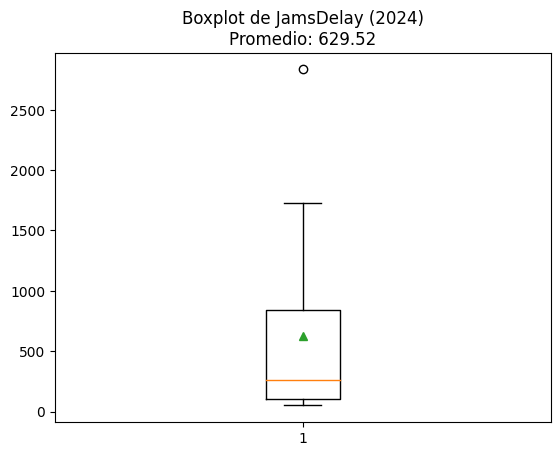

In [ ]:
# Crear boxplot para observar el comportamiento de los minutos de congestion JamsDelay

# obtener promedio para mostrarlo en título
mean_value = merged['JamsDelay'].mean()
plt.boxplot(merged[merged['year'] == 2024]['JamsDelay'],showmeans=True)
plt.title(f'Boxplot de JamsDelay (2024)\nPromedio: {mean_value:.2f}')
plt.show()


<div class="alert alert-block alert-success">
<b>Comentario del Revisor [1° iteración]</b> <a class="tocSkip"></a><br>
<b>Éxito</b>

Buen uso del boxplot para analizar la distribución y la media de la congestión vehicular.
</div>

(array([1., 0., 3., 3., 3., 2., 1., 1., 0., 1.]),
 array([ 2277. ,  4666.9,  7056.8,  9446.7, 11836.6, 14226.5, 16616.4,
        19006.3, 21396.2, 23786.1, 26176. ]),
 <BarContainer object of 10 artists>)

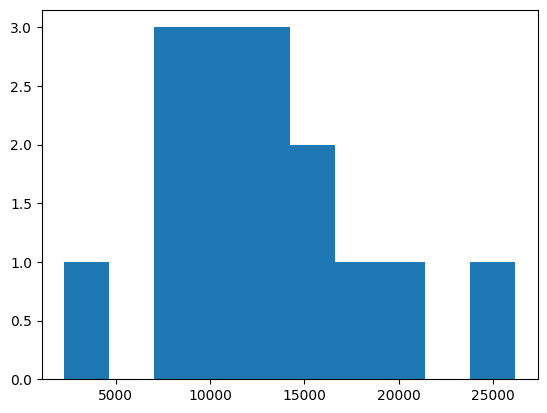

In [ ]:
# Crear histograma para ver la distribución de la economía (city_gdp_capita)
plt.hist(merged['city_gdp_capita'],bins=10)


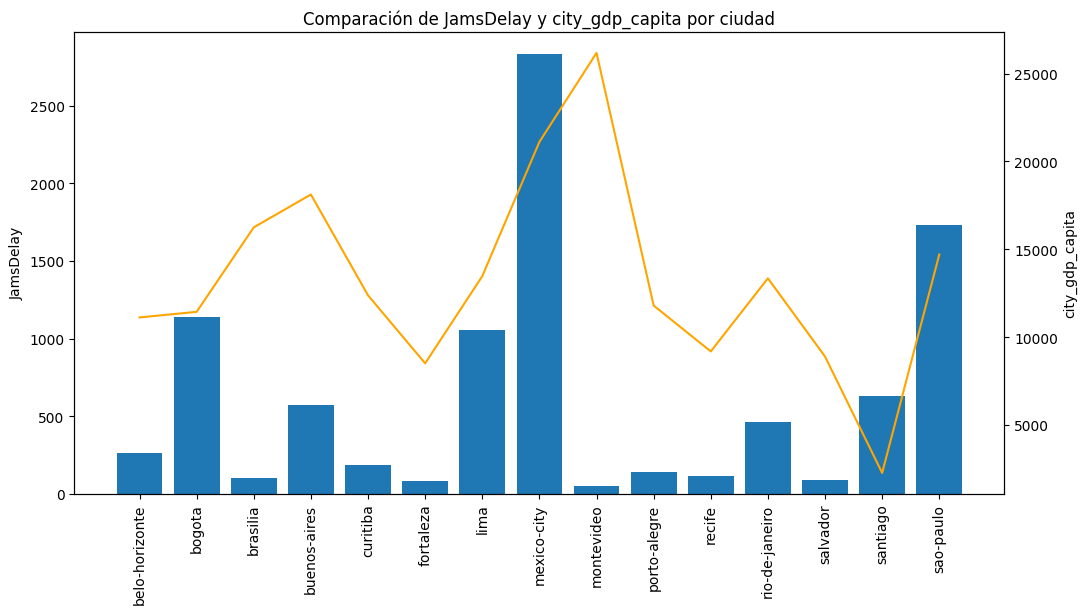

In [ ]:
# Gráfico de barras para comparar jams_delay y city_gdp_capita por ciudad

fig, ax1 = plt.subplots(figsize=(12, 6))

# Primer eje Y: JamsDelay (barras)
ax1.bar(merged['City'], merged['JamsDelay'])
ax1.set_ylabel('JamsDelay')
ax1.tick_params(axis='x', rotation=90)

# Segundo eje Y: city_gdp_capita (línea)
ax2 = ax1.twinx()
ax2.plot(merged['City'], merged['city_gdp_capita'],color='orange')
ax2.set_ylabel('city_gdp_capita')

plt.title('Comparación de JamsDelay y city_gdp_capita por ciudad')
plt.show()


<div class="alert alert-block alert-warning">
<b>Comentario del Revisor [1° iteración]</b> <a class="tocSkip"></a><br>
<b>Atención</b>

¿Te has fijado en las escalas de ambas variables? Al graficarlas juntas en un gráfico de barras con el mismo eje y, la diferencia numérica tan grande entre JamsDelay y city_gdp_capita hace que una de ellas no se aprecie bien. ¿Cómo podrías solucionar esto o qué alternativa se te ocurre para visualizar ambas métricas adecuadamente?
</div>

<div class="alert alert-block alert-success">
<b>Comentario del Revisor [2° iteración]</b> <a class="tocSkip"></a><br>
<b>Éxito</b>

Has utilizado correctamente un eje secundario con twinx para representar dos métricas con escalas numéricas diferentes, logrando una comparación visual limpia y efectiva.
</div>

In [ ]:
print(merged['JamsDelay'].describe())
print(merged.shape)

count      15.000000
mean      629.517204
std       783.063726
min        50.201092
25%       107.165938
50%       263.047879
75%       841.079053
max      2833.057892
Name: JamsDelay, dtype: float64
(15, 14)


**Tip:** Antes del `plt.show()` agrega el código `plt.xticks(rotation=90)` para rotar las etiquetas del eje X en 90 grados.

### 🧠 **Reflexiona**
Excelente trabajo llegando a esta etapa del análisis. Antes de avanzar, revisa tus gráficos, tómate un momento para pensar:

* ¿Las ciudades con mayor PIB per cápita también presentan más congestión?

* ¿O sucede lo contrario, o no existe una relación clara?

Escribe tus comentarios:

En cuanto a si las ciudades con mayor PIB percapita apresentan mayor congestión podemos deducir que no ya que Montevideo es la ciudad con mayor ingreso y no tiene una congestion relevante como es el caso de Ciudad de México.

No existe una relación clara con esta muestra uya que hay ciudades con PIB elevado y congestión baja pero a la vez hay ciudades con PIB mas pegado a la mediana pero con congestion a revisar.


---

## 🧩Paso 7: Exportar y documentar resultados

En esta etapa final consolidarás todo tu trabajo: guardarás el dataset limpio y crearás un resumen que documente los resultados del proyecto.

### 7.1 Guardar dataset final

**🎯Objetivo:**
Generar un CSV limpio, reproducible y con columnas relevantes para análisis posterior.

**Instrucciones**

- Exporta el DataFrame `merged` con el nombre: `ladb_mobility_economy_2024_clean.csv`
- Usa `index=False` para no incluir el índice.


In [ ]:
# Exporta el dataset final como CSV
merged.to_csv("ladb_mobility_economy_2024_clean.csv", index=False)

Se estandarizaron los nombres de columnas a snake_case, se convirtieron las fechas a datetime y se limpiaron las cifras económicas (separadores decimales, símbolos de porcentaje y escalas de población). Las lecturas de tráfico de 2024 se promediaron por ciudad, país y año. Después se unieron con los indicadores económicos mediante un merge de tipo INNER sobre City y year, lo que dejó 15 filas, una por ciudad. Como validación visual se usaron un boxplot de JamsDelay, un histograma del PIB per cápita y una gráfica de barras comparativa.

Hallazgos iniciales

JamsDelay tiene una distribución muy desigual: la media es de 629.5 minutos, pero la mediana es de 263.0. Unas pocas ciudades con congestión muy alta elevan el promedio, por lo que la mediana describe mejor a la ciudad típica del conjunto.
La congestión más severa se observa en Ciudad de México (máximo de 2,833 minutos) y en São Paulo. Bogotá también aparece entre las más congestionadas.
Montevideo tiene el PIB per cápita más alto de la muestra y una congestión baja, lo que sugiere que mayor productividad no implica necesariamente mayor congestión.
La correlación entre JamsDelay y city_gdp_capita es de [r = completar con el resultado de corr()]. Con 15 observaciones, un coeficiente moderado no es estadísticamente sólido por sí solo.

Recomendaciones

La pregunta original pedía identificar una sola ciudad con la “mayor correlación”, pero una correlación requiere varios puntos y se calcula sobre el conjunto de ciudades, no sobre una. Por eso el análisis se centra en la relación general y en los casos atípicos.
Ciudad de México y São Paulo son candidatas prioritarias para revisar inversión en transporte, por ser las de mayor congestión medida. Esta recomendación debe validarse antes de asignar recursos.
Validar las fuentes de congestión, ya que los datos en tiempo real pueden no representar el promedio anual de cada ciudad.

Ampliar la muestra con más años y ciudades, y considerar unemployment_pct y population como variables de control para separar el efecto de la movilidad del efecto del tamaño y el empleo de cada ciudad.
